In [5]:
import tarfile
import gzip
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from numpy.polynomial import Polynomial
from scipy.signal import savgol_filter, find_peaks
from scipy.optimize import curve_fit
from scipy.optimize import minimize_scalar
import requests
from pathlib import Path
from IPython.display import display

ModuleNotFoundError: No module named 'requests'

In [ ]:
descargas = {
    "J_PASP_107_1042.tar.gz": "https://cdsarc.cds.unistra.fr/viz-bin/nph-Cat/tar.gz?J/PASP/107/1042",
    "J_ApJS_94_221.tar.gz":   "https://cdsarc.cds.unistra.fr/viz-bin/nph-Cat/tar.gz?J/ApJS/94/221",
}

for nombre, url in descargas.items():
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    with open(nombre, "wb") as f:
        f.write(r.content)
    print(f"{nombre}: listo ({len(r.content)/1e6:.1f} MB)")

J_PASP_107_1042.tar.gz: listo (9.0 MB)
J_ApJS_94_221.tar.gz: listo (0.5 MB)


In [ ]:
tar = tarfile.open("J_PASP_107_1042.tar.gz","r:*")
tar.extractall("espectros", filter='data')

tar2 = tarfile.open("J_ApJS_94_221.tar.gz","r:*")
tar2.extractall("lineas", filter='data')

In [ ]:
spectral_files = [
    name for name in tar.getnames()
    if "ab" in name and name.endswith(".gz")
]

print(len(spectral_files))

310


In [ ]:
all_spectra = []

for file_name in spectral_files:

    file = tar.extractfile(file_name)

    with gzip.open(file, 'rt') as f:
        df = pd.read_csv(
            f,
            sep=r'\s+',
            header=None
        )


    temp = pd.DataFrame({
        "wavenumber": df[0],
        "intensity": df[1]
    })

    all_spectra.append(temp)

Sabemos que $$\lambda =
\frac{1}{\tilde{\nu}}$$

Y $$1 cm = 10^{8} Å$$

In [ ]:
spectra = pd.concat(all_spectra)

spectra = spectra.drop_duplicates(
    subset="wavenumber"
)


spectra.head()

spectra["lambda"] = 1e8 / spectra["wavenumber"]

spectra = spectra.sort_values("lambda")

print(spectra)

      wavenumber  intensity        lambda
1420    10953.40    0.57325   9129.585334
1419    10953.36    0.56870   9129.618674
1418    10953.32    0.58553   9129.652014
1417    10953.28    0.62694   9129.685355
1416    10953.24    0.65616   9129.718695
...          ...        ...           ...
4        1866.04    0.00000  53589.419305
3        1866.03    0.00000  53589.706489
2        1866.02    0.00000  53589.993676
1        1866.01    0.00000  53590.280867
0        1866.00    0.00000  53590.568060

[347034 rows x 3 columns]


In [ ]:
spectra["wavenumber"] = pd.to_numeric(spectra["wavenumber"], errors='coerce')
spectra["intensity"] = pd.to_numeric(spectra["intensity"], errors='coerce')
spectra = spectra.dropna(subset=["wavenumber", "intensity"])

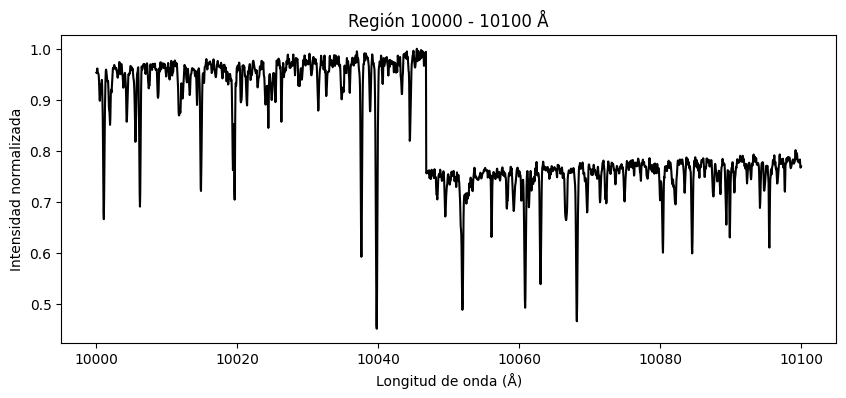

In [ ]:
lambdai = 10000
lambdaf = 10100

region = spectra[
    (spectra["lambda"] > lambdai) &
    (spectra["lambda"] < lambdaf)
]

plt.figure(figsize=(10,4))

plt.plot(
    region["lambda"],
    region["intensity"],
    color="black"
)

plt.xlabel("Longitud de onda (Å)")
plt.ylabel("Intensidad normalizada")

plt.title(f"Región {lambdai} - {lambdaf} Å")

plt.show()

In [ ]:
file = tar2.extractfile("./table2.gz")
with gzip.open(file,'rt') as f:

    lines = pd.read_fwf(
        f,
        colspecs=[
            (0,4),      # Num
            (5,15),     # Term1
            (15,16),    # -
            (16,26),    # Term2
            (27,28),    # J1
            (28,29),    # -
            (29,30),    # J2
            (30,36),    # I
            (37,47),    # Lvac
            (48,58),    # Lair
            (59,65),    # Lo-R
            (65,75),    # Sigma
            (76,77),    # q_Sigma
            (79,83),    # So-R
            (84,89),    # El
            (90,95),    # Eu
            (96,105),   # Elc
            (106,115),  # Euc
            (116,122),  # loggf
            (123,124),  # source
            (126,131)   # Blend
        ]
    )

lines.columns = [
"Num","Term1","dash1","Term2","J1","dash2","J2",
"I","Lvac","Lair","LoR","Sigma","qSigma","SoR",
"El","Eu","Elc","Euc","loggf","source","Blend"
]

 En el catálogo dice que las unidades de Lvac están en 0.1nm = 1Å, así que no hay que convertir nada. Usamos Lvacío porque con los datos de Hinkle se usó un interferómetro de transformada de Fourier.

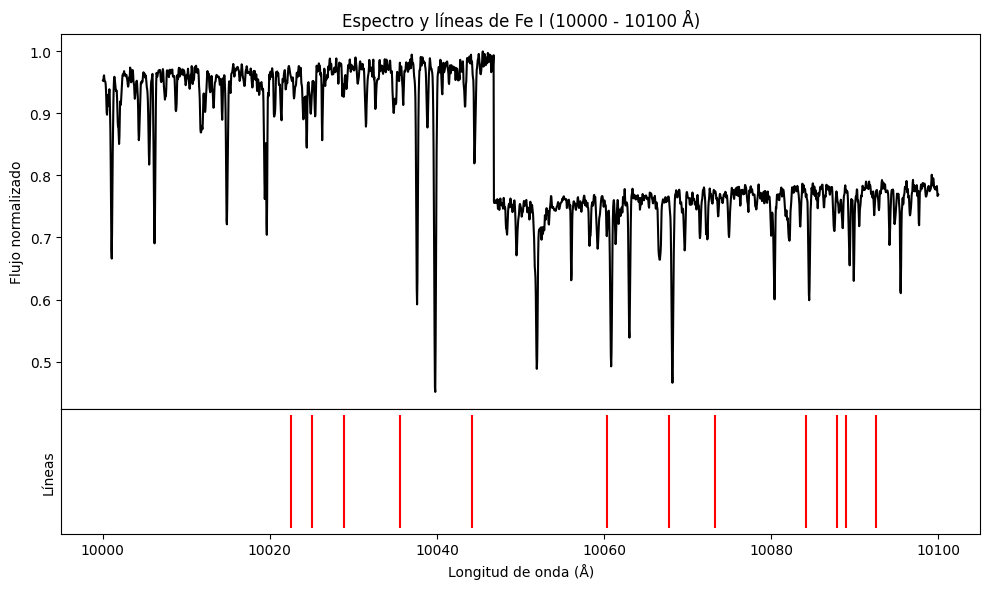

In [ ]:
lines["lambda"] = lines["Lvac"]

fe_lines = lines[
    lines["qSigma"] == "A"
]

lambda_min = 10000
lambda_max = 10100

copy_fe_lines = fe_lines.copy()
copy_fe_lines = copy_fe_lines[
    (copy_fe_lines["lambda"] > lambda_min) &
    (copy_fe_lines["lambda"] < lambda_max)
]

espectro = spectra.copy()
espectro = espectro[
    (espectro["lambda"] > lambda_min) &
    (espectro["lambda"] < lambda_max)
]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})


ax1.plot(espectro["lambda"], espectro["intensity"], color="black")
ax1.set_ylabel("Flujo normalizado")
ax1.set_title(f"Espectro y líneas de Fe I ({lambda_min} - {lambda_max} Å)")


ax2.vlines(
    copy_fe_lines["lambda"],
    ymin=0,
    ymax=1,
    color="red"
)
ax2.set_ylabel("Líneas")
ax2.set_xlabel("Longitud de onda (Å)")
ax2.set_yticks([])


plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.show()

In [ ]:
z_identificacion = 0.000045
fe_lines = fe_lines.copy()
fe_lines["lambda"] = pd.to_numeric(
    fe_lines["Lvac"],
    errors="coerce"
)

fe_lines = fe_lines.dropna(
    subset=["lambda"]
).copy()

fe_lines["lambda_identificacion"] = (
    fe_lines["lambda"] * (1 + z_identificacion)
)

fe_lines = fe_lines.sort_values(
    "lambda_identificacion"
).reset_index(drop=True)

In [ ]:
ventana_busqueda = 0.65
desplazamiento_maximo = 0.65
ventana_blending = 1.3
ventana_blending1 = 1.3
fraccion_blending = 0.50
tolerancia_doblete = 0.12
ventana_contexto = 1
fraccion_muy_corta = 0.9
fraccion_minimos_parecidos = 0.3
maximo_minimos_parecidos = 4
umbral_ruido_minimo = 0.06
profundidad_minima_absoluta = 0.10

def analizar_linea(lambda_id, espectro):

    res_vacio = {
        "lambda_obs": np.nan, "intensidad": np.nan, "nivel_local": np.nan, "profundidad_principal": np.nan,
        "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
        "minimo_contexto": np.nan, "profundidad_contexto": np.nan, "fraccion_contexto": np.nan,
        "resultado": "MUY CORTA"
    }

    # 1. Busqueda en ventana principal
    datos = espectro[
        (espectro["lambda"] >= lambda_id - ventana_busqueda) &
        (espectro["lambda"] <= lambda_id + ventana_busqueda)
    ].copy()

    if len(datos) < 3:
        return res_vacio

    x = datos["lambda"].to_numpy()
    y = datos["intensity"].to_numpy()
    valido = np.isfinite(x) & np.isfinite(y)
    x, y = x[valido], y[valido]

    if len(x) < 3:
        return res_vacio

    indices_minimos = [i for i in range(1, len(y) - 1) if y[i] < y[i - 1] and y[i] < y[i + 1]]

    if len(indices_minimos) == 0:
        return res_vacio

    nivel_local = np.max(y)
    candidatos = []

    for i in indices_minimos:
        profundidad_i = nivel_local - y[i]
        distancia_i = abs(x[i] - lambda_id)
        candidatos.append({
            "indice": i, "lambda": x[i], "intensidad": y[i],
            "profundidad": profundidad_i, "distancia": distancia_i
        })

    candidatos_validos = [c for c in candidatos if c["distancia"] <= desplazamiento_maximo]

    if len(candidatos_validos) == 0:
        res_vacio["resultado"] = "DESPLAZADA"
        return res_vacio

    indice_principal = min(
        range(len(candidatos_validos)),
        key=lambda j: (-candidatos_validos[j]["profundidad"], candidatos_validos[j]["distancia"])
    )

    principal = candidatos_validos[indice_principal]
    lambda_obs = principal["lambda"]
    intensidad_principal = principal["intensidad"]
    profundidad_principal = principal["profundidad"]

    if profundidad_principal < profundidad_minima_absoluta:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
            "minimo_contexto": np.nan, "profundidad_contexto": np.nan, "fraccion_contexto": np.nan,
            "resultado": "MUY CORTA"
        }

    # 2. Evaluacion MUCHOS MINIMOS
    datos_muchos = espectro[
        (espectro["lambda"] >= lambda_obs - ventana_blending1) &
        (espectro["lambda"] <= lambda_obs + ventana_blending1)
    ].copy()

    xm, ym = datos_muchos["lambda"].to_numpy(), datos_muchos["intensity"].to_numpy()
    valido_m = np.isfinite(xm) & np.isfinite(ym)
    xm, ym = xm[valido_m], ym[valido_m]

    indices_muchos = [i for i in range(1, len(ym) - 1) if ym[i] < ym[i - 1] and ym[i] < ym[i + 1]]
    nivel_local_m = np.max(ym) if len(ym) > 0 else nivel_local

    minimos_parecidos = []
    for i in indices_muchos:
        profundidad_i = nivel_local_m - ym[i]
        if (profundidad_i >= fraccion_minimos_parecidos * profundidad_principal) and (profundidad_i >= umbral_ruido_minimo):
            minimos_parecidos.append(i)

    if len(minimos_parecidos) >= maximo_minimos_parecidos:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
            "minimo_contexto": np.nan, "profundidad_contexto": np.nan, "fraccion_contexto": np.nan,
            "resultado": "MUCHOS MINIMOS"
        }

    # 3. Evaluacion de Blending y MEGA BLENDING
    datos_blend = espectro[
        (espectro["lambda"] >= lambda_obs - ventana_blending) &
        (espectro["lambda"] <= lambda_obs + ventana_blending)
    ].copy()

    xb, yb = datos_blend["lambda"].to_numpy(), datos_blend["intensity"].to_numpy()
    valido_b = np.isfinite(xb) & np.isfinite(yb)
    xb, yb = xb[valido_b], yb[valido_b]

    indices_blend = [i for i in range(1, len(yb) - 1) if yb[i] < yb[i - 1] and yb[i] < yb[i + 1]]
    candidatos_secundarios = []

    for i in indices_blend:
        if np.isclose(xb[i], lambda_obs, atol=0.001):
            continue
        profundidad_i = nivel_local - yb[i]
        fraccion_i = (profundidad_i / profundidad_principal) if profundidad_principal > 0 else np.nan
        candidatos_secundarios.append({
            "lambda": xb[i], "intensidad": yb[i], "profundidad": profundidad_i, "fraccion": fraccion_i
        })

    lambda_blend, profundidad_segunda, fraccion_blend = np.nan, np.nan, np.nan
    hay_blend = False

    significativos = [c for c in candidatos_secundarios
                      if np.isfinite(c["fraccion"])
                      and c["fraccion"] >= fraccion_blending
                      and c["profundidad"] >= umbral_ruido_minimo]

    if len(significativos) > 1:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
            "minimo_contexto": np.nan, "profundidad_contexto": np.nan, "fraccion_contexto": np.nan,
            "resultado": "MEGA BLENDING"
        }
    elif len(significativos) == 1:
        segunda = significativos[0]
        lambda_blend = segunda["lambda"]
        profundidad_segunda = segunda["profundidad"]
        fraccion_blend = segunda["fraccion"]
        hay_blend = True

    # 4. Evaluacion de contexto cuando no hay blending
    if not hay_blend:
        datos_contexto = espectro[
            (espectro["lambda"] >= lambda_obs - ventana_contexto) &
            (espectro["lambda"] <= lambda_obs + ventana_contexto)
        ].copy()

        xc, yc = datos_contexto["lambda"].to_numpy(), datos_contexto["intensity"].to_numpy()
        valido_c = np.isfinite(xc) & np.isfinite(yc)
        xc, yc = xc[valido_c], yc[valido_c]

        indices_contexto = [i for i in range(1, len(yc) - 1) if yc[i] < yc[i - 1] and yc[i] < yc[i + 1]]
        candidatos_contexto = []

        for i in indices_contexto:
            if np.isclose(xc[i], lambda_obs, atol=0.001):
                continue
            profundidad_i = nivel_local - yc[i]
            candidatos_contexto.append({"lambda": xc[i], "intensidad": yc[i], "profundidad": profundidad_i})

        minimo_contexto, profundidad_contexto, fraccion_contexto = np.nan, np.nan, np.nan

        if len(candidatos_contexto) > 0:
            contexto_profundo = max(candidatos_contexto, key=lambda dato: dato["profundidad"])
            minimo_contexto = contexto_profundo["lambda"]
            profundidad_contexto = contexto_profundo["profundidad"]
            if profundidad_contexto > 0:
                fraccion_contexto = profundidad_principal / profundidad_contexto

        resultado = "MUY CORTA" if (np.isfinite(fraccion_contexto) and fraccion_contexto <= fraccion_muy_corta) else "¡Línea Buena!"

        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
            "minimo_contexto": minimo_contexto, "profundidad_contexto": profundidad_contexto,
            "fraccion_contexto": fraccion_contexto, "resultado": resultado
        }

    # 5. Validacion de Doblete con Catalogo
    separacion_observada = abs(lambda_blend - lambda_obs)

    catalogo_cercano = fe_lines[
        (fe_lines["lambda_identificacion"] >= lambda_id - (ventana_busqueda + ventana_blending)) &
        (fe_lines["lambda_identificacion"] <= lambda_id + (ventana_busqueda + ventana_blending)) &
        (abs(fe_lines["lambda_identificacion"] - lambda_id) > 0.001)
    ].copy()

    hay_doblete = False

    if len(catalogo_cercano) > 0:
        catalogo_cercano["separacion_catalogo"] = abs(catalogo_cercano["lambda_identificacion"] - lambda_id)
        diferencias = abs(catalogo_cercano["separacion_catalogo"] - separacion_observada)
        indice_mejor = diferencias.idxmin()
        separacion_catalogo = catalogo_cercano.loc[indice_mejor, "separacion_catalogo"]

        if separacion_catalogo > 0:
            diferencia_relativa = abs(separacion_observada - separacion_catalogo) / separacion_catalogo
            if diferencia_relativa <= tolerancia_doblete:
                hay_doblete = True

    if not hay_doblete:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": lambda_blend, "profundidad_segunda": profundidad_segunda,
            "fraccion_blend": fraccion_blend, "minimo_contexto": np.nan,
            "profundidad_contexto": np.nan, "fraccion_contexto": np.nan,
            "resultado": "BLENDING"
        }

    # 6. Evaluacion de componentes de Doblete
    def evaluar_componente(lambda_objetivo, profundidad_objetivo, lambda_otra):
        datos_contexto = espectro[
            (espectro["lambda"] >= lambda_objetivo - ventana_contexto) &
            (espectro["lambda"] <= lambda_objetivo + ventana_contexto)
        ].copy()

        xc, yc = datos_contexto["lambda"].to_numpy(), datos_contexto["intensity"].to_numpy()
        valido = np.isfinite(xc) & np.isfinite(yc)
        xc, yc = xc[valido], yc[valido]

        indices_contexto = [j for j in range(1, len(yc) - 1) if yc[j] < yc[j - 1] and yc[j] < yc[j + 1]]
        candidatos_contexto = []

        for j in indices_contexto:
            if np.isclose(xc[j], lambda_objetivo, atol=0.001) or np.isclose(xc[j], lambda_otra, atol=0.001):
                continue
            profundidad_j = nivel_local - yc[j]
            candidatos_contexto.append({"lambda": xc[j], "profundidad": profundidad_j})

        if len(candidatos_contexto) == 0:
            return np.nan, np.nan, np.nan, False

        contexto_profundo = max(candidatos_contexto, key=lambda dato: dato["profundidad"])
        minimo_contexto = contexto_profundo["lambda"]
        profundidad_contexto = contexto_profundo["profundidad"]

        fraccion_contexto = (profundidad_objetivo / profundidad_contexto) if profundidad_contexto > 0 else np.nan
        componente_corta = np.isfinite(fraccion_contexto) and (fraccion_contexto <= fraccion_muy_corta)

        return minimo_contexto, profundidad_contexto, fraccion_contexto, componente_corta

    contexto_p, prof_ctx_p, frac_ctx_p, principal_corta = evaluar_componente(lambda_obs, profundidad_principal, lambda_blend)
    contexto_s, prof_ctx_s, frac_ctx_s, secundaria_corta = evaluar_componente(lambda_blend, profundidad_segunda, lambda_obs)

    if not principal_corta and not secundaria_corta:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": lambda_blend, "profundidad_segunda": profundidad_segunda,
            "fraccion_blend": fraccion_blend, "minimo_contexto": np.nan,
            "profundidad_contexto": np.nan, "fraccion_contexto": np.nan,
            "resultado": "DOBLETE BUENO"
        }
    elif not principal_corta and secundaria_corta:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
            "minimo_contexto": contexto_p, "profundidad_contexto": prof_ctx_p,
            "fraccion_contexto": frac_ctx_p, "resultado": "¡Línea Buena!"
        }
    else:
        return {
            "lambda_obs": lambda_obs, "intensidad": intensidad_principal,
            "nivel_local": nivel_local, "profundidad_principal": profundidad_principal,
            "lambda_blend": np.nan, "profundidad_segunda": np.nan, "fraccion_blend": np.nan,
            "minimo_contexto": contexto_s if principal_corta else contexto_p,
            "profundidad_contexto": prof_ctx_s if principal_corta else prof_ctx_p,
            "fraccion_contexto": frac_ctx_s if principal_corta else frac_ctx_p,
            "resultado": "MUY CORTA"
        }

# ============================================================
# BUCLE PRINCIPAL Y PRINTS
# ============================================================
resultados_lista = []

for i, fila in fe_lines.iterrows():
    resultado = analizar_linea(fila["lambda_identificacion"], spectra)
    resultado["Num"] = fila["Num"]
    resultado["lambda_catalogo"] = fila["lambda"]
    resultado["lambda_id"] = fila["lambda_identificacion"]
    resultados_lista.append(resultado)

resultados = pd.DataFrame(resultados_lista)

print("Lineas Fe I calidad A:", len(fe_lines))
print("LINEAS BUENAS:", (resultados["resultado"] == "¡Línea Buena!").sum())
print("DOBLETES BUENOS:", (resultados["resultado"] == "DOBLETE BUENO").sum())
print("BLENDING:", (resultados["resultado"] == "BLENDING").sum())
print("MEGA BLENDING:", (resultados["resultado"] == "MEGA BLENDING").sum())
print("MUCHOS MINIMOS:", (resultados["resultado"] == "MUCHOS MINIMOS").sum())
print("MUY CORTAS:", (resultados["resultado"] == "MUY CORTA").sum())
print("DESPLAZADAS:", (resultados["resultado"] == "DESPLAZADA").sum())

Lineas Fe I calidad A: 4517
LINEAS BUENAS: 415
DOBLETES BUENOS: 29
BLENDING: 243
MEGA BLENDING: 82
MUCHOS MINIMOS: 284
MUY CORTAS: 3464
DESPLAZADAS: 0


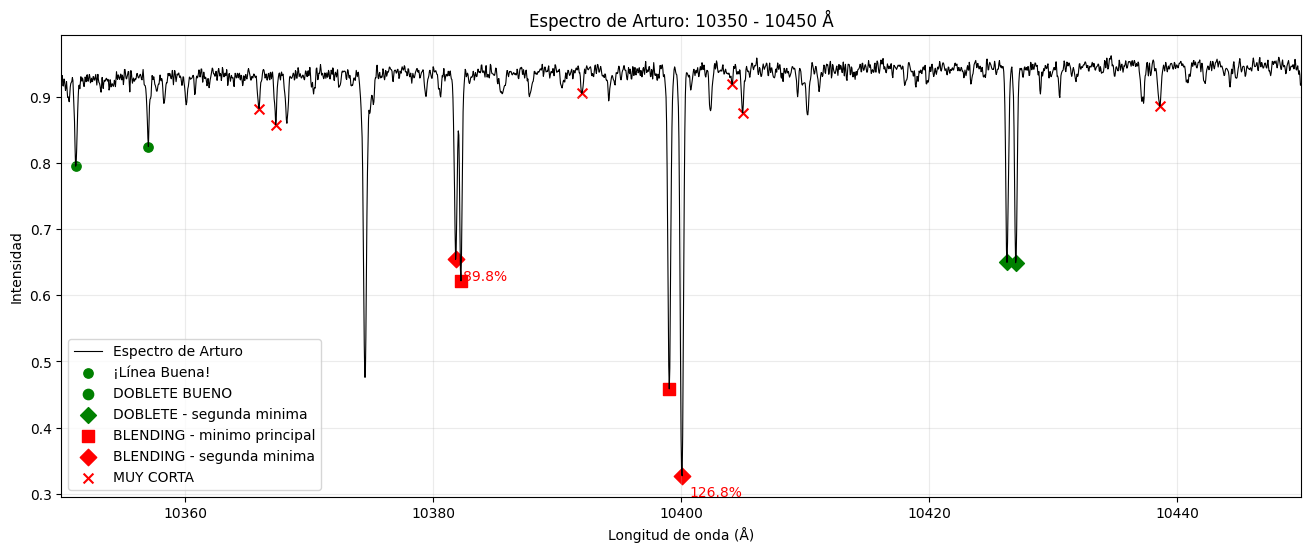

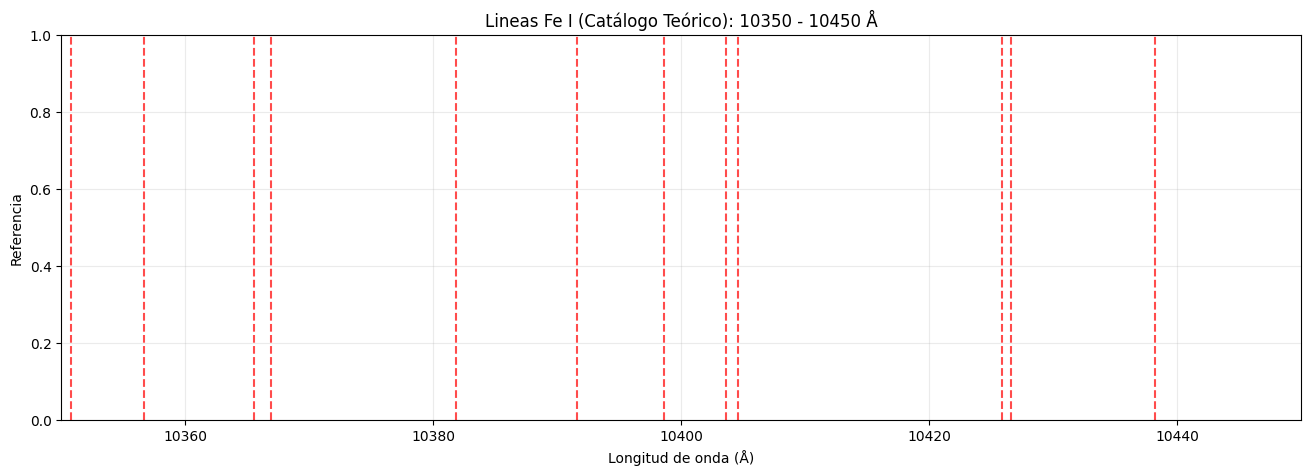

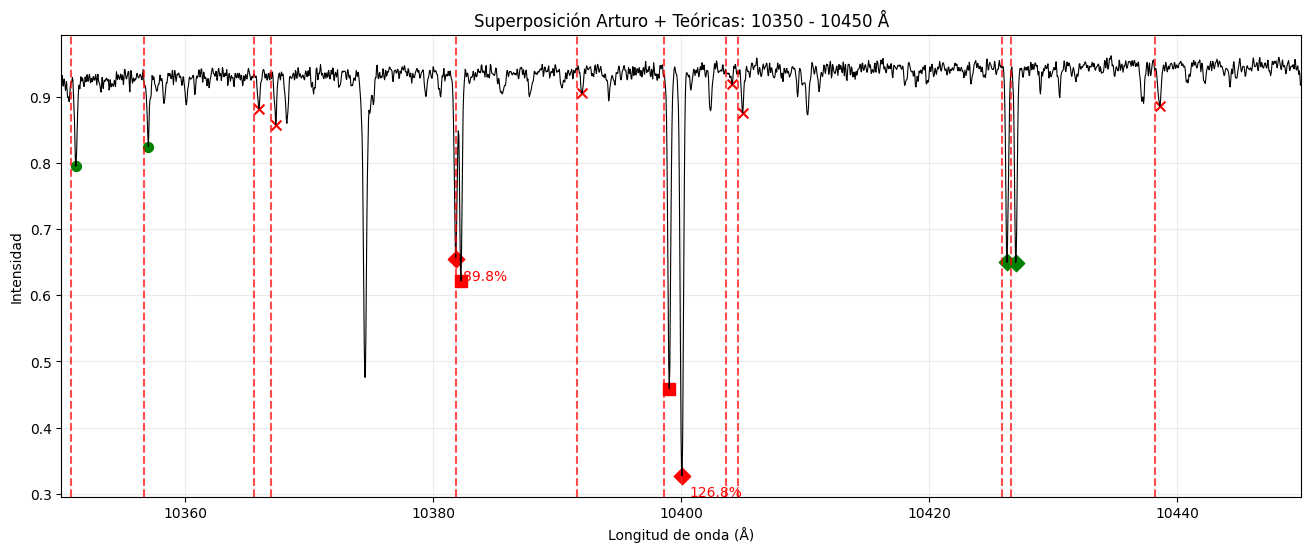

,Num,lambda_catalogo,lambda_obs,profundidad_principal,lambda_blend,profundidad_segunda,fraccion_blend,minimo_contexto,profundidad_contexto,fraccion_contexto,resultado
0,1995,10350.802,10351.152497,0.13532,NaN,NaN,NaN,10350.638220,0.03781,3.578947,¡Línea Buena!
1,1994,10356.644,10357.027450,0.11664,NaN,NaN,NaN,10357.714011,0.03303,3.531335,¡Línea Buena!
2,1993,10365.544,10365.959846,0.05901,NaN,NaN,NaN,NaN,NaN,NaN,MUY CORTA
3,1995,10366.902,10367.292436,0.07974,NaN,NaN,NaN,NaN,NaN,NaN,MUY CORTA
4,267,10381.846,10382.232263,0.31989,10381.801118,0.28733,0.898215,NaN,NaN,NaN,BLENDING
5,1994,10391.591,10391.985701,0.04179,NaN,NaN,NaN,NaN,NaN,NaN,MUY CORTA
6,267,10398.646,10399.031642,0.49015,10400.069888,0.62157,1.268122,NaN,NaN,NaN,BLENDING
7,2076,10403.629,10404.095052,0.03018,NaN,NaN,NaN,NaN,NaN,NaN,MUY CORTA
8,905,10404.565,10404.961085,0.07248,NaN,NaN,NaN,NaN,NaN,NaN,MUY CORTA
9,620,10425.887,10426.267521,0.29762,10426.963293,0.29814,1.001747,NaN,NaN,NaN,DOBLETE BUENO


In [ ]:
def mostrar_region(lambda_min_region, lambda_max_region):

    region = spectra[
        (spectra["lambda"] >= lambda_min_region) &
        (spectra["lambda"] <= lambda_max_region)
    ].copy()

    # Se usa lambda_catalogo en lugar de lambda_id
    resultados_region = resultados[
        (resultados["lambda_catalogo"] >= lambda_min_region) &
        (resultados["lambda_catalogo"] <= lambda_max_region)
    ].copy()

    correctas_region = resultados_region[
        resultados_region["resultado"] == "¡Línea Buena!"
    ].copy()

    dobletes_region = resultados_region[
        resultados_region["resultado"] == "DOBLETE BUENO"
    ].copy()

    blending_region = resultados_region[
        resultados_region["resultado"] == "BLENDING"
    ].copy()

    muy_cortas_region = resultados_region[
        resultados_region["resultado"] == "MUY CORTA"
    ].copy()

    muchos_minimos_region = resultados_region[
        resultados_region["resultado"] == "MUCHOS MINIMOS"
    ].copy()

    # ========================================================
    # GRAFICA 1: ESPECTRO Y PUNTOS DETECTADOS
    # ========================================================

    plt.figure(figsize=(16, 6))

    plt.plot(
        region["lambda"],
        region["intensity"],
        linewidth=0.8,
        color="black",
        label="Espectro de Arturo"
    )

    # --------------------------------------------------------
    # LINEAS BUENAS
    # --------------------------------------------------------
    if len(correctas_region) > 0:
        correctas_plot = correctas_region.dropna(subset=["lambda_obs"])
        intensidades = []

        for lambda_obs in correctas_plot["lambda_obs"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_obs)).argmin()
            intensidades.append(region["intensity"].iloc[indice])

        plt.scatter(
            correctas_plot["lambda_obs"],
            intensidades,
            s=45,
            marker="o",
            color="green",
            label="¡Línea Buena!"
        )

    # --------------------------------------------------------
    # DOBLETES BUENOS
    # --------------------------------------------------------
    if len(dobletes_region) > 0:
        dobletes_plot = dobletes_region.dropna(subset=["lambda_obs"])
        intensidades_principal = []

        for lambda_obs in dobletes_plot["lambda_obs"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_obs)).argmin()
            intensidades_principal.append(region["intensity"].iloc[indice])

        plt.scatter(
            dobletes_plot["lambda_obs"],
            intensidades_principal,
            s=55,
            marker="o",
            color="green",
            label="DOBLETE BUENO"
        )

        dobletes_secundario = dobletes_plot.dropna(subset=["lambda_blend"])
        intensidades_secundarias = []

        for lambda_blend in dobletes_secundario["lambda_blend"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_blend)).argmin()
            intensidades_secundarias.append(region["intensity"].iloc[indice])

        if len(dobletes_secundario) > 0:
            plt.scatter(
                dobletes_secundario["lambda_blend"],
                intensidades_secundarias,
                s=65,
                marker="D",
                color="green",
                label="DOBLETE - segunda minima"
            )

    # --------------------------------------------------------
    # BLENDING
    # --------------------------------------------------------
    if len(blending_region) > 0:
        blending_plot = blending_region.dropna(subset=["lambda_obs"])
        intensidades_principal = []

        for lambda_obs in blending_plot["lambda_obs"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_obs)).argmin()
            intensidades_principal.append(region["intensity"].iloc[indice])

        plt.scatter(
            blending_plot["lambda_obs"],
            intensidades_principal,
            s=65,
            marker="s",
            color="red",
            label="BLENDING - minimo principal"
        )

        blending_secundario = blending_plot.dropna(subset=["lambda_blend"])
        intensidades_secundarias = []

        for lambda_blend in blending_secundario["lambda_blend"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_blend)).argmin()
            intensidades_secundarias.append(region["intensity"].iloc[indice])

        if len(blending_secundario) > 0:
            plt.scatter(
                blending_secundario["lambda_blend"],
                intensidades_secundarias,
                s=70,
                marker="D",
                color="red",
                label="BLENDING - segunda minima"
            )

            for j, (_, fila) in enumerate(blending_secundario.iterrows()):
                lambda_blend = fila["lambda_blend"]
                porcentaje = fila["fraccion_blend"] * 100
                intensidad_blend = intensidades_secundarias[j]

                plt.annotate(
                    f"{porcentaje:.1f}%",
                    (lambda_blend, intensidad_blend),
                    xytext=(5, -15),
                    textcoords="offset points",
                    fontsize=10,
                    color="red"
                )

    # --------------------------------------------------------
    # MUY CORTA
    # --------------------------------------------------------
    if len(muy_cortas_region) > 0:
        muy_cortas_plot = muy_cortas_region.dropna(subset=["lambda_obs"])
        intensidades = []

        for lambda_obs in muy_cortas_plot["lambda_obs"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_obs)).argmin()
            intensidades.append(region["intensity"].iloc[indice])

        plt.scatter(
            muy_cortas_plot["lambda_obs"],
            intensidades,
            s=50,
            marker="x",
            color="red",
            label="MUY CORTA"
        )

    # --------------------------------------------------------
    # MUCHOS MINIMOS
    # --------------------------------------------------------
    if len(muchos_minimos_region) > 0:
        muchos_plot = muchos_minimos_region.dropna(subset=["lambda_obs"])
        intensidades = []

        for lambda_obs in muchos_plot["lambda_obs"]:
            indice = (np.abs(region["lambda"].to_numpy() - lambda_obs)).argmin()
            intensidades.append(region["intensity"].iloc[indice])

        plt.scatter(
            muchos_plot["lambda_obs"],
            intensidades,
            s=50,
            marker="^",
            color="blue",
            label="Mezcla"
        )

    plt.xlim(lambda_min_region, lambda_max_region)
    plt.xlabel("Longitud de onda (Å)")
    plt.ylabel("Intensidad")
    plt.title(f"Espectro de Arturo: {lambda_min_region} - {lambda_max_region} Å")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    # ========================================================
    # GRAFICA 2: SOLO LINEAS TEORICAS
    # ========================================================

    plt.figure(figsize=(16, 5))

    nave_region = fe_lines[
        (fe_lines["lambda"] >= lambda_min_region) &
        (fe_lines["lambda"] <= lambda_max_region)
    ].copy()

    # Nave original teórica unicamente
    for lambda_nave in nave_region["lambda"]:
        plt.axvline(
            lambda_nave,
            linestyle="--",
            alpha=0.7,
            color="red"
        )

    plt.xlim(lambda_min_region, lambda_max_region)
    plt.xlabel("Longitud de onda (Å)")
    plt.ylabel("Referencia")
    plt.title(f"Lineas Fe I (Catálogo Teórico): {lambda_min_region} - {lambda_max_region} Å")
    plt.grid(alpha=0.25)
    plt.show()

    # ========================================================
    # GRAFICA 3: SUPERPOSICION TOTAL
    # ========================================================

    plt.figure(figsize=(16, 6))

    plt.plot(
        region["lambda"],
        region["intensity"],
        linewidth=0.8,
        color="black",
        label="Espectro de Arturo"
    )

    # --------------------------------------------------------
    # Líneas Teóricas
    # --------------------------------------------------------
    for lambda_teo in nave_region["lambda"]:
        plt.axvline(
            lambda_teo,
            linestyle="--",
            alpha=0.7,
            color="red"
        )

    # --------------------------------------------------------
    # Resultados
    # --------------------------------------------------------
    for _, fila in resultados_region.iterrows():
        lambda_obs = fila["lambda_obs"]

        if not np.isfinite(lambda_obs):
            continue

        indice = (np.abs(region["lambda"].to_numpy() - lambda_obs)).argmin()
        intensidad_obs = region["intensity"].iloc[indice]

        # CORRECTA
        if fila["resultado"] == "¡Línea Buena!":
            plt.scatter(
                lambda_obs, intensidad_obs,
                s=50, marker="o", color="green"
            )

        # DOBLETE BUENO
        elif fila["resultado"] == "DOBLETE BUENO":
            plt.scatter(
                lambda_obs, intensidad_obs,
                s=60, marker="o", color="green"
            )
            lambda_blend = fila["lambda_blend"]
            if np.isfinite(lambda_blend):
                indice_blend = (np.abs(region["lambda"].to_numpy() - lambda_blend)).argmin()
                intensidad_blend = region["intensity"].iloc[indice_blend]
                plt.scatter(
                    lambda_blend, intensidad_blend,
                    s=70, marker="D", color="green"
                )

        # BLENDING
        elif fila["resultado"] == "BLENDING":
            plt.scatter(
                lambda_obs, intensidad_obs,
                s=65, marker="s", color="red"
            )
            lambda_blend = fila["lambda_blend"]
            if np.isfinite(lambda_blend):
                indice_blend = (np.abs(region["lambda"].to_numpy() - lambda_blend)).argmin()
                intensidad_blend = region["intensity"].iloc[indice_blend]
                plt.scatter(
                    lambda_blend, intensidad_blend,
                    s=70, marker="D", color="red"
                )
                porcentaje = fila["fraccion_blend"] * 100
                plt.annotate(
                    f"{porcentaje:.1f}%",
                    (lambda_blend, intensidad_blend),
                    xytext=(5, -15), textcoords="offset points",
                    fontsize=10, color="red"
                )

        # MUY CORTA
        elif fila["resultado"] == "MUY CORTA":
            plt.scatter(
                lambda_obs, intensidad_obs,
                s=50, marker="x", color="red"
            )
            if np.isfinite(fila["minimo_contexto"]):
                lambda_contexto = fila["minimo_contexto"]
                indice_contexto = (np.abs(region["lambda"].to_numpy() - lambda_contexto)).argmin()
                intensidad_contexto = region["intensity"].iloc[indice_contexto]
                plt.scatter(
                    lambda_contexto, intensidad_contexto,
                    s=55, marker="^", color="red"
                )
                if np.isfinite(fila["fraccion_contexto"]):
                    porcentaje_contexto = fila["fraccion_contexto"] * 100
                    plt.annotate(
                        f"{porcentaje_contexto:.1f}%",
                        (lambda_contexto, intensidad_contexto),
                        xytext=(5, -15), textcoords="offset points",
                        fontsize=10, color="red"
                    )

        # MUCHOS MINIMOS
        elif fila["resultado"] == "MUCHOS MINIMOS":
            plt.scatter(
                lambda_obs, intensidad_obs,
                s=50, marker="^", color="blue", label="Mezcla"
            )

    plt.xlim(lambda_min_region, lambda_max_region)
    plt.xlabel("Longitud de onda (Å)")
    plt.ylabel("Intensidad")
    plt.title(f"Superposición Arturo + Teóricas: {lambda_min_region} - {lambda_max_region} Å")
    plt.grid(alpha=0.25)

    plt.show()

    # ========================================================
    # TABLA DE RESULTADOS
    # ========================================================

    # Se eliminó la columna "lambda_id" de la lista a mostrar
    tabla_region = resultados_region[
        [
            "Num",
            "lambda_catalogo",
            "lambda_obs",
            "profundidad_principal",
            "lambda_blend",
            "profundidad_segunda",
            "fraccion_blend",
            "minimo_contexto",
            "profundidad_contexto",
            "fraccion_contexto",
            "resultado"
        ]
    ].sort_values("lambda_catalogo").reset_index(drop=True)

    display(tabla_region)


# ============================================================
# ELEGIR LA REGION
# ============================================================

lambda_min_region = 10350
lambda_max_region = 10450

# ============================================================
# EJECUTAR
# ============================================================

mostrar_region(
    lambda_min_region,
    lambda_max_region
)

In [ ]:
lambda_min = 9180
lambda_max = 9230

# Filtrar solo líneas correctas en esa región
correctas_excel = resultados[
    (resultados["lambda_id"] >= lambda_min) &
    (resultados["lambda_id"] <= lambda_max) &
    (resultados["resultado"] == "¡Línea Buena!")
].copy()

# Ordenar por longitud de onda
correctas_excel = correctas_excel.sort_values(
    "lambda_id"
).reset_index(drop=True)

# Nombre del archivo
nombre_archivo = (
    f"Lineas_correctas_{lambda_min}_{lambda_max}.xlsx"
)

# Exportar a Excel
correctas_excel.to_excel(
    nombre_archivo,
    index=False
)

print(
    f"Se exportaron {len(correctas_excel)} líneas correctas."
)
print(f"Archivo: {nombre_archivo}")

Se exportaron 3 líneas correctas.
Archivo: Lineas_correctas_9180_9230.xlsx


,lambda_obs,lambda_catalogo,resultado,componente,lambda_izquierda,lambda_derecha,ancho_valle,fraccion_parada,n_puntos,grado,flujo_observado,flujo_ajustado,nivel_local,profundidad_centro,velocidad_kms,rmse,R2,tercera_derivada,error_cv
0,10044.476944,10044.224,¡Línea Buena!,principal,10044.355876,10044.719089,0.363214,0.40,6,3,0.81948,0.81948,0.991652,0.172172,7.549680,0.015464,0.920305,-114.256607,0.020209
1,10060.848009,10060.400,¡Línea Buena!,principal,10060.645572,10061.050454,0.404883,0.35,10,4,0.49222,0.49222,0.760390,0.268170,13.350329,0.003882,0.997832,11.356171,0.011137
2,10068.181727,10067.804,¡Línea Buena!,principal,10067.978994,10068.384467,0.405473,0.35,10,4,0.46577,0.46577,0.771408,0.305638,11.247696,0.009332,0.989178,1.093692,0.018787
3,10084.548858,10084.158,¡Línea Buena!,principal,10084.304788,10084.792939,0.488151,0.20,12,4,0.59885,0.59885,0.781634,0.182784,11.619827,0.011072,0.966894,2.191335,0.018174


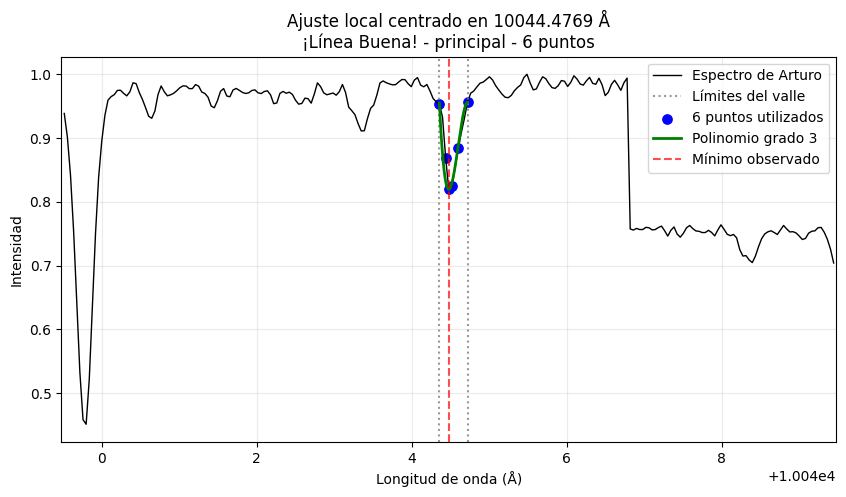

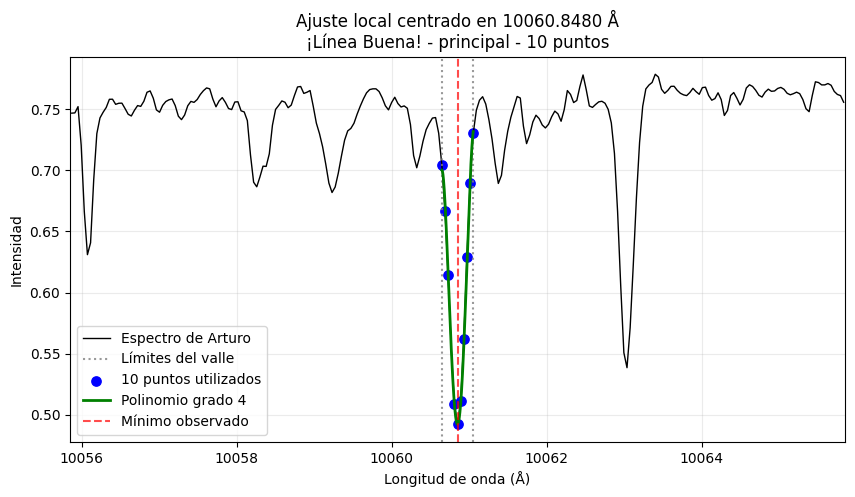

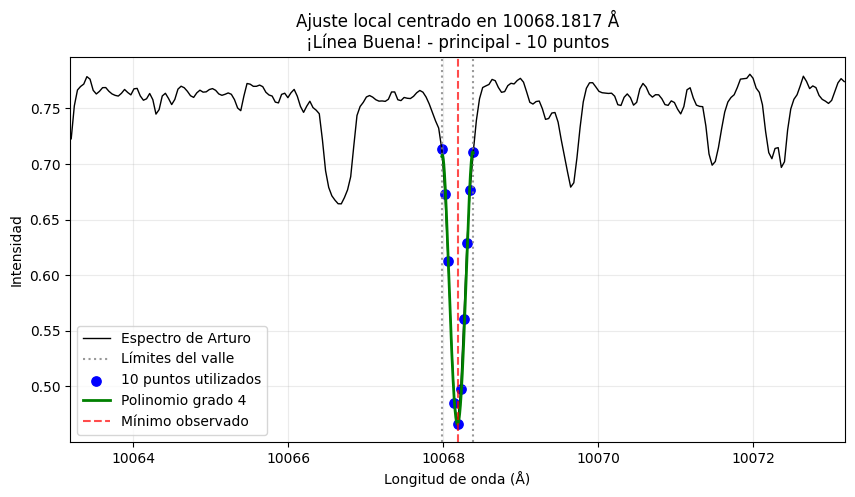

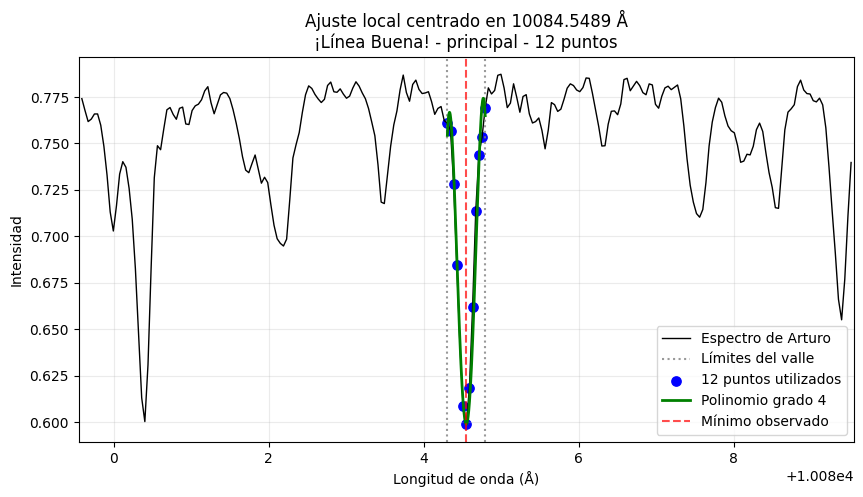


Resumen de la seleccion automatica:


,lambda_obs,resultado,componente,fraccion_parada,ancho_valle,n_puntos,grado,error_cv
0,10044.476944,¡Línea Buena!,principal,0.40,0.363214,6,3,0.020209
1,10060.848009,¡Línea Buena!,principal,0.35,0.404883,10,4,0.011137
2,10068.181727,¡Línea Buena!,principal,0.35,0.405473,10,4,0.018787
3,10084.548858,¡Línea Buena!,principal,0.20,0.488151,12,4,0.018174


In [ ]:
# ============================================================
# AJUSTE POLINOMIAL LOCAL Y DISTRIBUCIÓN (CÓDIGO OPTIMIZADO)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# PARÁMETROS Y REGIÓN
# ============================================================
lambda_min_region, lambda_max_region = 10000, 10100
min_puntos, max_puntos = 5, 13
fracciones_parada = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
puntos_consecutivos = 3
ventana_maxima_valle = 1.5
distancia_proteccion = 1.5
tolerancia_cv = 0.10

# Filtrar región
region = spectra[(spectra["lambda"] >= lambda_min_region) & (spectra["lambda"] <= lambda_max_region)].copy()

# ============================================================
# FUNCIONES BASE OPTIMIZADAS
# ============================================================

def ajustar_polinomio_restringido(x, y, lambda0, flujo_centro, grado):
    """Ajusta un polinomio con P(0)=flujo_centro y P'(0)=0"""
    if grado not in (3, 4): return None, None

    x_centrada = x - lambda0
    # Construcción dinámica de la matriz A
    A = np.column_stack([x_centrada ** i for i in range(2, grado + 1)])
    objetivo = y - flujo_centro

    try:
        coef_libres = np.linalg.lstsq(A, objetivo, rcond=None)[0]
        # Ensamblar coeficientes: [a_n, ..., a_2, a_1=0, a_0=flujo_centro]
        coefs = np.concatenate((coef_libres[::-1], [0.0, flujo_centro]))
        return np.poly1d(coefs), coefs
    except:
        return None, None

def error_validacion_cruzada(x, y, lambda0, flujo_centro, grado):
    """Calcula el RMSE usando Leave-One-Out Cross Validation"""
    indice_centro = np.abs(x - lambda0).argmin()
    errores = []

    for i in range(len(x)):
        if i == indice_centro: continue

        mascara = np.ones(len(x), dtype=bool)
        mascara[i] = False

        polinomio, _ = ajustar_polinomio_restringido(x[mascara], y[mascara], lambda0, flujo_centro, grado)
        if polinomio is None: return np.inf

        errores.append((y[i] - polinomio(x[i] - lambda0)) ** 2)

    return np.sqrt(np.mean(errores)) if errores else np.inf

def encontrar_valle(x, y, lambda0, fraccion_parada):
    """Encuentra los límites izquierdo y derecho del valle"""
    if len(x) < 3: return None

    indice_centro = np.abs(x - lambda0).argmin()
    flujo_centro = y[indice_centro]
    nivel_local = np.percentile(y, 90)

    if not np.isfinite(nivel_local) or not np.isfinite(flujo_centro): return None

    profundidad = nivel_local - flujo_centro
    if profundidad <= 0: return None

    umbral = nivel_local - (fraccion_parada * profundidad)

    def buscar_limite(indices):
        contador_fuera = 0
        idx_limite = indice_centro
        for idx in indices:
            contador_fuera = 0 if y[idx] <= umbral else contador_fuera + 1
            if contador_fuera >= puntos_consecutivos: break
            idx_limite = idx
        return idx_limite

    # Lado Izquierdo
    idx_izq_validos = np.where((x >= lambda0 - ventana_maxima_valle) & (x <= lambda0))[0][::-1]
    indice_limite_izq = buscar_limite(idx_izq_validos)

    # Lado Derecho
    idx_der_validos = np.where((x >= lambda0) & (x <= lambda0 + ventana_maxima_valle))[0]
    indice_limite_der = buscar_limite(idx_der_validos)

    return {
        "lambda_izquierda": x[indice_limite_izq],
        "lambda_derecha": x[indice_limite_der],
        "flujo_centro": flujo_centro,
        "nivel_local": nivel_local,
        "profundidad": profundidad,
        "umbral": umbral,
        "fraccion_parada": fraccion_parada
    }

def seleccionar_puntos_valle(x, y, lambda0, n_puntos, valle):
    """Selecciona índices distribuidos equitativamente a ambos lados del valle"""
    if valle is None: return None

    indices_valle = np.where((x >= valle["lambda_izquierda"]) & (x <= valle["lambda_derecha"]))[0]
    if len(indices_valle) < n_puntos: return None

    izquierda = [i for i in indices_valle if x[i] < lambda0]
    derecha = [i for i in indices_valle if x[i] > lambda0]

    n_izq = (n_puntos - 1) // 2
    n_der = (n_puntos - 1) - n_izq

    if len(izquierda) < n_izq or len(derecha) < n_der: return None

    # Selección uniforme de puntos
    pos_izq = np.linspace(0, len(izquierda) - 1, n_izq, dtype=int)
    pos_der = np.linspace(0, len(derecha) - 1, n_der, dtype=int)

    indices = sorted(set([np.abs(x - lambda0).argmin()] + [izquierda[p] for p in pos_izq] + [derecha[p] for p in pos_der]))

    if len(indices) != n_puntos: return None

    resultado = valle.copy()
    resultado["indices"] = indices
    return resultado

# ============================================================
# CONSTRUCCIÓN DE OBJETIVOS
# ============================================================
objetivos = []

for _, fila in resultados.iterrows():
    l_obs, l_cat, res, l_blend = fila["lambda_obs"], fila["lambda_catalogo"], fila["resultado"], fila.get("lambda_blend", np.nan)
    if not np.isfinite(l_obs) or not (lambda_min_region <= l_obs <= lambda_max_region): continue

    if res == "¡Línea Buena!":
        objetivos.append({"lambda_obs": l_obs, "lambda_catalogo": l_cat, "resultado": res, "componente": "principal"})
    elif res == "DOBLETE BUENO":
        objetivos.append({"lambda_obs": l_obs, "lambda_catalogo": l_cat, "resultado": res, "componente": "principal"})
        if np.isfinite(l_blend) and (lambda_min_region <= l_blend <= lambda_max_region):
            objetivos.append({
                "lambda_obs": l_blend,
                "lambda_catalogo": l_cat + (l_blend - l_obs),
                "resultado": res,
                "componente": "secundaria"
            })

objetivos.sort(key=lambda x: x["lambda_obs"])

# ============================================================
# AJUSTE PRINCIPAL
# ============================================================
ajustes_region = []
velocidad_luz = 299792.458

for k, obj in enumerate(objetivos):
    lambda0 = obj["lambda_obs"]

    # Límites protegidos por líneas vecinas
    izq_gen = max(lambda_min_region, lambda0 - ventana_maxima_valle)
    der_gen = min(lambda_max_region, lambda0 + ventana_maxima_valle)

    if k > 0 and (lambda0 - objetivos[k-1]["lambda_obs"]) <= distancia_proteccion:
        izq_gen = max(izq_gen, (objetivos[k-1]["lambda_obs"] + lambda0) / 2)
    if k < len(objetivos) - 1 and (objetivos[k+1]["lambda_obs"] - lambda0) <= distancia_proteccion:
        der_gen = min(der_gen, (lambda0 + objetivos[k+1]["lambda_obs"]) / 2)

    # Filtrar datos locales
    datos_locales = spectra[(spectra["lambda"] >= izq_gen) & (spectra["lambda"] <= der_gen)]
    x, y = datos_locales["lambda"].to_numpy(), datos_locales["intensity"].to_numpy()
    valido = np.isfinite(x) & np.isfinite(y)
    x, y = x[valido], y[valido]

    if len(x) < min_puntos: continue

    candidatos = []
    for frac_parada in fracciones_parada:
        valle = encontrar_valle(x, y, lambda0, frac_parada)
        if not valle: continue

        valle["lambda_izquierda"] = max(valle["lambda_izquierda"], izq_gen)
        valle["lambda_derecha"] = min(valle["lambda_derecha"], der_gen)

        for n_pts in range(min_puntos, max_puntos + 1):
            seleccion = seleccionar_puntos_valle(x, y, lambda0, n_pts, valle)
            if not seleccion: continue

            idx_fit = seleccion["indices"]
            x_fit, y_fit = x[idx_fit], y[idx_fit]
            grado = 3 if n_pts <= 8 else 4

            polinomio, coefs = ajustar_polinomio_restringido(x_fit, y_fit, lambda0, seleccion["flujo_centro"], grado)
            if polinomio is None: continue

            error_cv = error_validacion_cruzada(x_fit, y_fit, lambda0, seleccion["flujo_centro"], grado)
            if not np.isfinite(error_cv): continue

            residuales = y_fit - polinomio(x_fit - lambda0)
            candidatos.append({
                **valle, "fraccion_parada": frac_parada, "n_puntos": n_pts, "grado": grado,
                "error_cv": error_cv, "rmse": np.sqrt(np.mean(residuales ** 2)), "coeficientes": coefs,
                "x_fit": x_fit.copy(), "y_fit": y_fit.copy(), "lambda_izquierda": valle["lambda_izquierda"],
                "lambda_derecha": valle["lambda_derecha"], "umbral": valle["umbral"]
            })

    if not candidatos: continue

    # Seleccionar el mejor modelo
    mejor_error = min(c["error_cv"] for c in candidatos)
    equivs = [c for c in candidatos if c["error_cv"] <= mejor_error * (1 + tolerancia_cv)]
    mejor = min(equivs, key=lambda c: (c["lambda_derecha"] - c["lambda_izquierda"], c["n_puntos"]))

    # Cálculos estadísticos finales
    poly_final = np.poly1d(mejor["coeficientes"])
    y_ajustado = poly_final(mejor["x_fit"] - lambda0)
    ss_res = np.sum((mejor["y_fit"] - y_ajustado) ** 2)
    ss_tot = np.sum((mejor["y_fit"] - np.mean(mejor["y_fit"])) ** 2)

    velocidad_kms = (velocidad_luz * (lambda0 - obj["lambda_catalogo"]) / obj["lambda_catalogo"]) if np.isfinite(obj["lambda_catalogo"]) else np.nan

    ajustes_region.append({
        "lambda_obs": lambda0, "lambda_catalogo": obj["lambda_catalogo"], "resultado": obj["resultado"],
        "componente": obj["componente"], "lambda_izquierda": mejor["lambda_izquierda"],
        "lambda_derecha": mejor["lambda_derecha"], "ancho_valle": mejor["lambda_derecha"] - mejor["lambda_izquierda"],
        "fraccion_parada": mejor["fraccion_parada"], "n_puntos": mejor["n_puntos"], "grado": mejor["grado"],
        "flujo_observado": mejor["flujo_centro"], "flujo_ajustado": poly_final(0.0),
        "nivel_local": mejor["nivel_local"], "profundidad_centro": mejor["profundidad"],
        "umbral_nucleo": mejor["umbral"], "velocidad_kms": velocidad_kms, "rmse": mejor["rmse"],
        "R2": (1 - ss_res / ss_tot) if ss_tot > 0 else np.nan,
        "tercera_derivada": np.polyder(poly_final, 3)(0.0), "error_cv": mejor["error_cv"],
        "x_fit": mejor["x_fit"].tolist(), "y_fit": mejor["y_fit"].tolist(), "coeficientes": mejor["coeficientes"]
    })

df_ajustes_region = pd.DataFrame(ajustes_region)

# ============================================================
# TABLA Y GRÁFICAS DE DETALLE
# ============================================================
if not df_ajustes_region.empty:
    columnas_mostrar = ["lambda_obs", "lambda_catalogo", "resultado", "componente", "lambda_izquierda", "lambda_derecha",
                        "ancho_valle", "fraccion_parada", "n_puntos", "grado", "flujo_observado", "flujo_ajustado",
                        "nivel_local", "profundidad_centro", "velocidad_kms", "rmse", "R2", "tercera_derivada", "error_cv"]
    display(df_ajustes_region[columnas_mostrar].sort_values("lambda_obs").reset_index(drop=True))

    for _, ajuste in df_ajustes_region.iterrows():
        l0 = ajuste["lambda_obs"]
        x_f, y_f = np.array(ajuste["x_fit"]), np.array(ajuste["y_fit"])
        poly = np.poly1d(ajuste["coeficientes"])

        reg_graf = spectra[(spectra["lambda"] >= l0 - 5.0) & (spectra["lambda"] <= l0 + 5.0)]
        x_curva = np.linspace(x_f.min(), x_f.max(), 300)

        plt.figure(figsize=(10, 5))
        plt.plot(reg_graf["lambda"], reg_graf["intensity"], color="black", linewidth=1.0, label="Espectro de Arturo")
        plt.axvline(ajuste["lambda_izquierda"], linestyle=":", color="gray", alpha=0.8, label="Límites del valle")
        plt.axvline(ajuste["lambda_derecha"], linestyle=":", color="gray", alpha=0.8)
        plt.scatter(x_f, y_f, s=45, color="blue", label=f"{int(ajuste['n_puntos'])} puntos utilizados")
        plt.plot(x_curva, poly(x_curva - l0), color="green", linewidth=2, label=f"Polinomio grado {int(ajuste['grado'])}")
        plt.axvline(l0, linestyle="--", color="red", alpha=0.7, label="Mínimo observado")

        plt.xlim(l0 - 5.0, l0 + 5.0)
        plt.xlabel("Longitud de onda (Å)")
        plt.ylabel("Intensidad")
        plt.title(f"Ajuste local centrado en {l0:.4f} Å\n{ajuste['resultado']} - {ajuste['componente']} - {int(ajuste['n_puntos'])} puntos")
        plt.legend()
        plt.grid(alpha=0.25)
        plt.show()

    print("\nResumen de la seleccion automatica:")
    display(df_ajustes_region[["lambda_obs", "resultado", "componente", "fraccion_parada", "ancho_valle", "n_puntos", "grado", "error_cv"]].sort_values("lambda_obs").reset_index(drop=True))
else:
    print("No hay lineas buenas o dobletes buenos en la region seleccionada.")

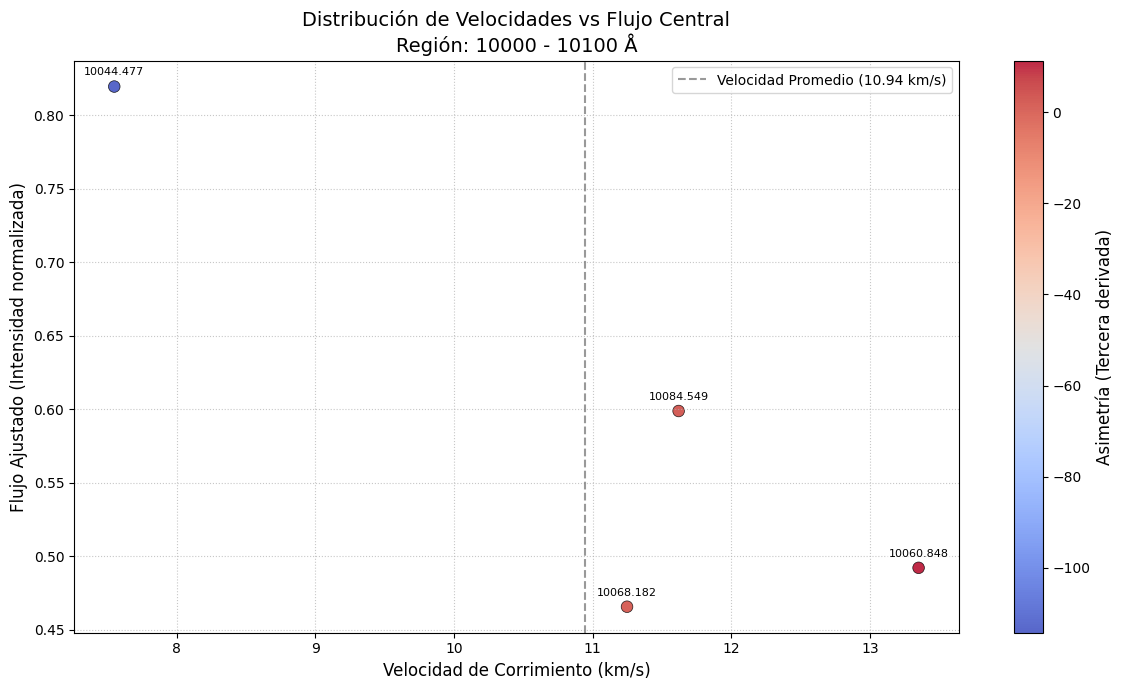

In [ ]:
# ============================================================
# GRÁFICA DE DISTRIBUCIÓN DE VELOCIDADES VS FLUJO CENTRAL
# CON ETIQUETAS DE LAMBDA ID
# ============================================================

if not df_ajustes_region.empty:
    plt.figure(figsize=(12, 7))

    # Filtrar valores NaN si los hay para evitar errores en la gráfica
    df_plot = df_ajustes_region.dropna(
        subset=["velocidad_kms", "flujo_ajustado", "tercera_derivada"]
    ).copy()

    if len(df_plot) > 0:
        # Crear el gráfico de dispersión
        # x: Velocidad en km/s calculada desde el polinomio
        # y: Flujo ajustado en el centro del valle
        # c: Tercera derivada (proxy de asimetría)
        scatter = plt.scatter(
            df_plot["velocidad_kms"],
            df_plot["flujo_ajustado"],
            c=df_plot["tercera_derivada"],
            cmap="coolwarm",
            edgecolor='k',
            linewidth=0.5,
            s=70,
            alpha=0.85
        )

        # Configurar la barra de color
        cbar = plt.colorbar(scatter)
        cbar.set_label("Asimetría (Tercera derivada)", fontsize=12)

        # Iterar sobre cada fila para ponerle la etiqueta (lambda id) a cada punto
        for _, fila in df_plot.iterrows():
            plt.annotate(
                f"{fila['lambda_obs']:.3f}", # Texto a mostrar (lambda_id con 3 decimales)
                (fila['velocidad_kms'], fila['flujo_ajustado']), # Coordenadas del punto
                textcoords="offset points",
                xytext=(0, 8), # Desplazar el texto 8 puntos hacia arriba
                ha='center',
                fontsize=8,
                color="black",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.5, lw=0) # Fondo semitransparente para que no se pierda con las líneas del grid
            )

        # Configuración del gráfico
        plt.xlabel("Velocidad de Corrimiento (km/s)", fontsize=12)
        plt.ylabel("Flujo Ajustado (Intensidad normalizada)", fontsize=12)
        plt.title(f"Distribución de Velocidades vs Flujo Central\nRegión: {lambda_min_region} - {lambda_max_region} Å", fontsize=14)

        # Línea de velocidad promedio
        vel_promedio = np.mean(df_plot["velocidad_kms"])
        plt.axvline(
            vel_promedio,
            color="gray",
            linestyle="--",
            alpha=0.8,
            label=f'Velocidad Promedio ({vel_promedio:.2f} km/s)'
        )

        plt.grid(True, linestyle=":", alpha=0.7)
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("Los datos ajustados contienen valores nulos que impiden graficar.")
else:
    print("No hay datos ajustados para generar la gráfica de distribución.")